# 01 · Data Exploration (G.2)

Exploration of the Enveda CASMI 2026 training and test data. Each section ends with the design decision it supports.
Figures are saved to `results/figures/` for the report and slides.

Run from the repo root after downloading the data to `data/raw/` (see README). Runtime about 2 minutes.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("../.."))  # repo root, so `src` imports work
os.chdir(os.path.abspath("../.."))

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.spectra import ADDUCT_DELTA, neutral_mass, formula_mass

FIG = "results/figures"
os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
C_TRAIN, C_NP, C_TEST = "#4C72B0", "#DD8452", "#55A868"

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Loading the data
The training file is 3 GB because of the peak arrays, so the metadata columns are loaded first. Peaks are sampled later.

In [2]:
META = ["ingest_lib", "inchikey14", "molecular_formula", "ionization_mode", "instrument_type", "adduct",
        "precursor_mz", "precursor_error_ppm", "num_peaks", "collision_energy_ev", "collision_energy_orig_units"]
train = pq.read_table("data/raw/train.parquet", columns=META).to_pandas()
test = pd.read_parquet("data/raw/test.parquet")
test["num_peaks"] = test.ms2_mzs.map(len)

train["mass"] = train.molecular_formula.map(formula_mass)
test["mass"] = [neutral_mass(p, a) for p, a in zip(test.precursor_mz, test.adduct)]
np_ex = train[train.ingest_lib == "enveda-np-examples"]

print(f"train: {len(train):,} spectra, {train.inchikey14.nunique():,} structures, {train.ingest_lib.nunique()} libraries")
print(f"test (public sample): {len(test):,} spectra, {test.molecule_id.nunique()} molecules")
print(f"enveda-np-examples: {len(np_ex):,} spectra, {np_ex.inchikey14.nunique()} structures")

train: 2,539,608 spectra, 275,810 structures, 11 libraries
test (public sample): 1,213 spectra, 400 molecules
enveda-np-examples: 1,184 spectra, 250 structures


## 2. Where the training data comes from

,spectra,structures,spectra_per_structure
ingest_lib,,,
enveda-180,1153785,182941,6.3
pluskal_ms2,527581,46821,11.3
riken,347171,15892,21.8
gnps,220849,45750,4.8
massbank,101727,9180,11.1
mona,92416,11681,7.9
spectraverse,50933,9631,5.3
msdial,40765,9127,4.5
drug_plus,2545,2539,1.0


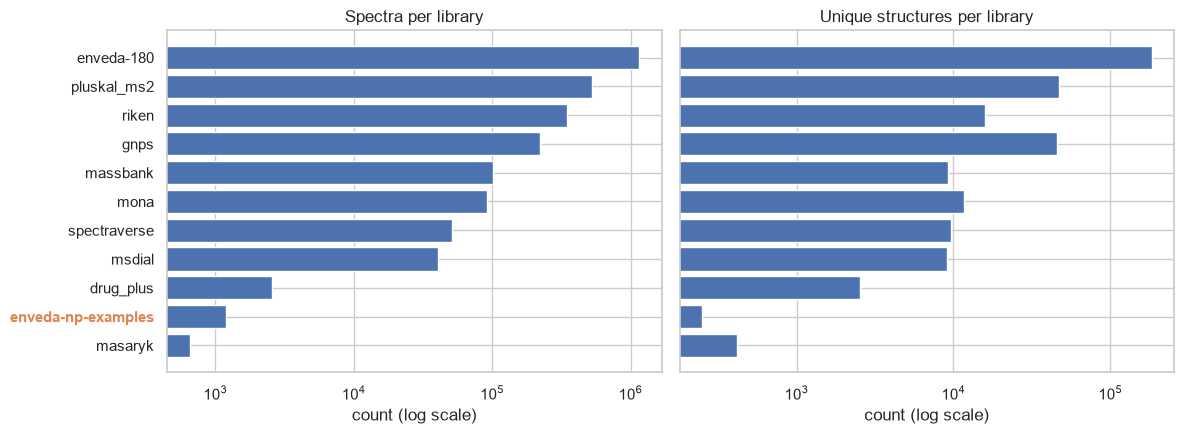

In [3]:
lib = (train.groupby("ingest_lib")
       .agg(spectra=("inchikey14", "size"), structures=("inchikey14", "nunique"))
       .sort_values("spectra"))
lib["spectra_per_structure"] = (lib.spectra / lib.structures).round(1)
display(lib.sort_values("spectra", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
ax[0].barh(lib.index, lib.spectra, color=C_TRAIN); ax[0].set_xscale("log"); ax[0].set_title("Spectra per library")
ax[1].barh(lib.index, lib.structures, color=C_TRAIN); ax[1].set_xscale("log"); ax[1].set_title("Unique structures per library")
for a in ax: a.set_xlabel("count (log scale)")
for a in ax:
    for lbl in a.get_yticklabels():
        if lbl.get_text() == "enveda-np-examples": lbl.set_color(C_NP); lbl.set_fontweight("bold")
save(fig, "eda_01_libraries")

**Decision:** enveda-180 is almost half the spectra but contains drug-like synthetic chemistry, not natural products.
`enveda-np-examples` is tiny but uses the test instrument and pipeline, so it is our **validation set**.

## 3. Is the validation molecule set findable in other libraries?

In [4]:
other = set(train.loc[train.ingest_lib != "enveda-np-examples", "inchikey14"])
np_keys = set(np_ex.inchikey14)
print(f"{len(np_keys & other)}/{len(np_keys)} enveda-np-examples structures also appear in another library "
      f"({len(np_keys & other)/len(np_keys):.0%})")
print(f"structures appearing in >1 library: {(train.groupby('inchikey14').ingest_lib.nunique() > 1).mean():.1%}")

250/250 enveda-np-examples structures also appear in another library (100%)
structures appearing in >1 library: 10.2%


**Decision:** all 250 validation molecules also appear in another library, so holding out `enveda-np-examples` tests *library search* ("Class 1" molecules) well.
It **cannot** measure Class 2/3 (molecules with no spectra, or novel ones), so local scores overestimate the leaderboard.
Any learned model must be validated with a **split by structure (`inchikey14`)**, otherwise the same compound leaks from another library.

## 4. Adducts and ionisation mode: train vs test

,train,enveda-np-examples,test
adduct,,,
[M+H]+,52.2,48.1,79.1
[M-H]-,18.3,23.3,15.9
other,14.3,0.0,0.0
[M+CH2O2-H]-,3.3,8.9,2.6
[M+NH4]+,2.1,8.3,0.3
[M+Na]+,7.0,6.8,1.8
[M-H2O+H]+,0.9,2.0,0.0
[M+K]+,0.7,1.4,0.2
[M+Cl]-,1.1,0.6,0.2


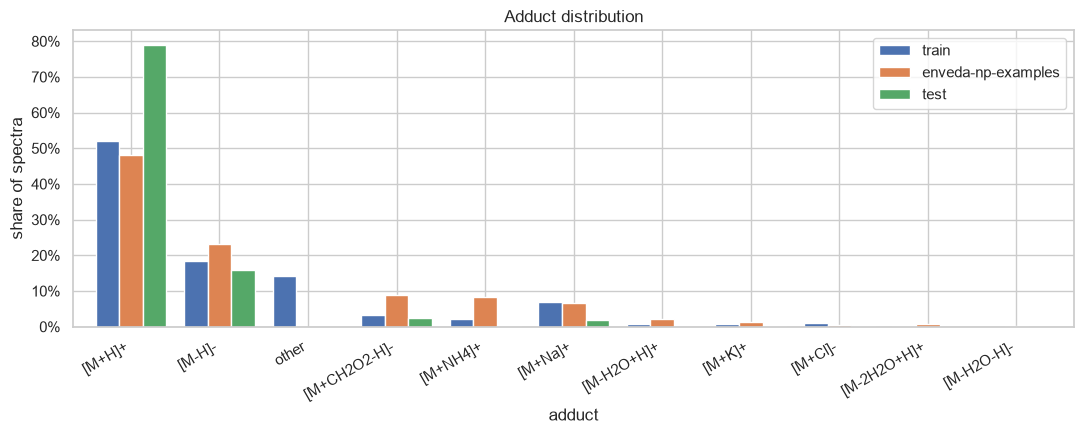

ionisation mode (test): {'positive': 0.814, 'negative': 0.186}
train spectra with an adduct outside the 10 test adducts: 14.3%


In [5]:
test_adducts = list(ADDUCT_DELTA)
def share(df):
    s = df.adduct.where(df.adduct.isin(test_adducts), "other").value_counts(normalize=True)
    return s
ad = pd.DataFrame({"train": share(train), "enveda-np-examples": share(np_ex), "test": share(test)}).fillna(0)
ad = ad.loc[ad.max(axis=1).sort_values(ascending=False).index]
display((ad * 100).round(1))

fig, ax = plt.subplots(figsize=(11, 4.5))
ad.plot.bar(ax=ax, color=[C_TRAIN, C_NP, C_TEST], width=0.8)
ax.set_ylabel("share of spectra"); ax.set_title("Adduct distribution"); ax.yaxis.set_major_formatter("{x:.0%}")
plt.xticks(rotation=30, ha="right")
save(fig, "eda_02_adducts")
print("ionisation mode (test):", test.ionization_mode.value_counts(normalize=True).round(3).to_dict())
print("train spectra with an adduct outside the 10 test adducts:", f"{(~train.adduct.isin(test_adducts)).mean():.1%}")

**Decision:** `[M+H]+` dominates. Negative mode is about 20% of test spectra, so the reference must keep both modes and compare **like with like** (same ionisation mode).
Training spectra with adducts the test never uses can be filtered out for learned models.

## 5. Molecule size (neutral mass)

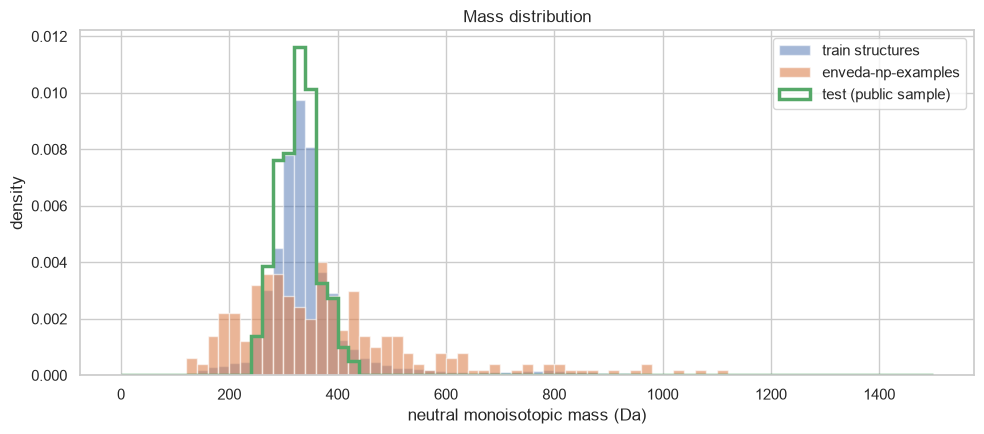

{'count': 275300.0, 'mean': 358.1, 'std': 132.8, 'min': 31.0, '25%': 304.2, '50%': 333.2, '75%': 366.1, 'max': 3399.6}


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(0, 1500, 76)
ax.hist(train.drop_duplicates("inchikey14").mass.dropna(), bins=bins, density=True, alpha=.5, color=C_TRAIN, label="train structures")
ax.hist(np_ex.drop_duplicates("inchikey14").mass.dropna(), bins=bins, density=True, alpha=.6, color=C_NP, label="enveda-np-examples")
ax.hist(test.drop_duplicates("molecule_id").mass.dropna(), bins=bins, density=True, histtype="step", lw=2.5, color=C_TEST, label="test (public sample)")
ax.set_xlabel("neutral monoisotopic mass (Da)"); ax.set_ylabel("density"); ax.set_title("Mass distribution"); ax.legend()
save(fig, "eda_03_mass")
print(train.drop_duplicates("inchikey14").mass.describe().round(1).to_dict())

## 6. The core difficulty: many structures share the same mass

,candidates,same_formula
count,250.0,250.0
mean,36.5,14.4
std,52.9,23.5
min,1.0,1.0
25%,6.0,3.0
50%,15.0,6.0
75%,42.8,15.8
90%,98.1,33.0
max,359.0,221.0


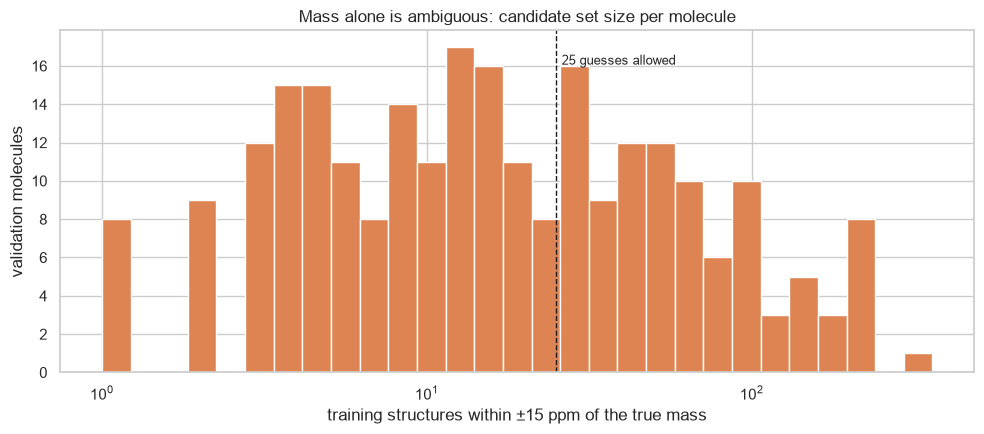

molecules with more than 25 candidates: 38%


In [7]:
structs = train.drop_duplicates("inchikey14")[["inchikey14", "molecular_formula", "mass"]].dropna().sort_values("mass")
m = structs.mass.values

def n_candidates(mass, ppm=15):
    tol = mass * ppm * 1e-6
    return np.searchsorted(m, mass + tol) - np.searchsorted(m, mass - tol)

q = np_ex.drop_duplicates("inchikey14")
q = q[q.mass.notna()]
q = q.assign(candidates=[n_candidates(x) for x in q.mass],
             same_formula=q.molecular_formula.map(structs.molecular_formula.value_counts()))
display(q[["candidates", "same_formula"]].describe(percentiles=[.25, .5, .75, .9]).round(1))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(q.candidates, bins=np.logspace(0, np.log10(q.candidates.max() + 1), 30), color=C_NP)
ax.set_xscale("log"); ax.set_xlabel("training structures within ±15 ppm of the true mass")
ax.set_ylabel("validation molecules"); ax.set_title("Mass alone is ambiguous: candidate set size per molecule")
ax.axvline(25, color="k", ls="--", lw=1); ax.text(26, ax.get_ylim()[1]*.9, "25 guesses allowed", fontsize=9)
save(fig, "eda_04_isomer_ambiguity")
print(f"molecules with more than 25 candidates: {(q.candidates > 25).mean():.0%}")

**Decision:** precursor mass narrows 275k structures to a candidate set, but many candidates are **isomers (same formula, same mass)** that mass cannot separate.
The fragment peaks are what distinguish them, which is why the baseline re-ranks candidates by spectral similarity.

## 7. Label quality: precursor mass error

,50%,95%,99%
ingest_lib,,,
spectraverse,0.7,2.3,4.9
masaryk,1.5,3.2,4.0
enveda-180,1.0,3.3,4.4
enveda-np-examples,1.6,3.7,6.6
msdial,1.5,4.2,6.0
drug_plus,1.7,5.6,76305.8
mona,1.8,125.4,54361.9
massbank,1.9,264.4,11269.1
riken,3.8,353.6,117516.3


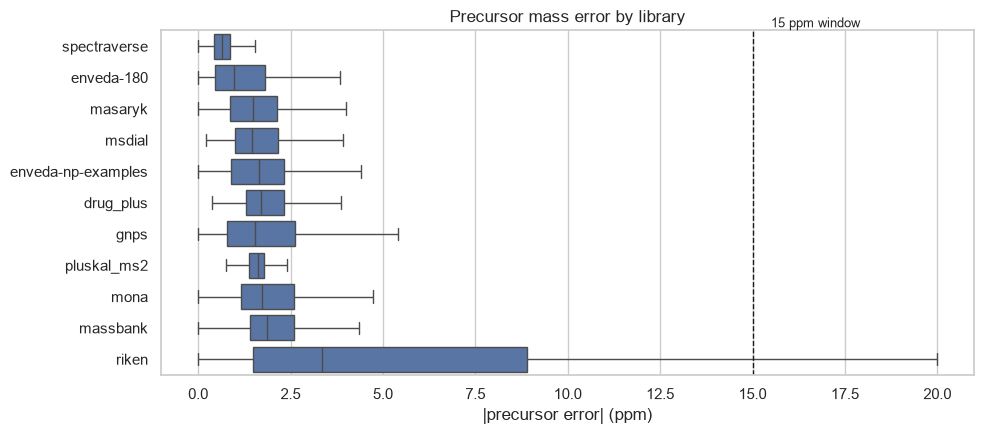

share of all spectra within 15 ppm: 94.6%;  timsTOF libs: 100.0%


In [8]:
err = train.dropna(subset=["precursor_error_ppm"]).assign(abs_err=lambda d: d.precursor_error_ppm.abs())
tab = err.groupby("ingest_lib").abs_err.describe(percentiles=[.5, .95, .99])[["50%", "95%", "99%"]].round(1)
display(tab.sort_values("95%"))

fig, ax = plt.subplots(figsize=(10, 4.5))
order = tab.sort_values("50%").index
sns.boxplot(data=err[err.abs_err < 100], y="ingest_lib", x="abs_err", order=order, ax=ax,
            showfliers=False, color=C_TRAIN)
ax.axvline(15, color="k", ls="--", lw=1); ax.text(15.5, -0.6, "15 ppm window", fontsize=9)
ax.set_xlabel("|precursor error| (ppm)"); ax.set_ylabel(""); ax.set_title("Precursor mass error by library")
save(fig, "eda_05_ppm_error")
print(f"share of all spectra within 15 ppm: {(err.abs_err <= 15).mean():.1%};  timsTOF libs: "
      f"{(err[err.ingest_lib.str.startswith('enveda')].abs_err <= 15).mean():.1%}")

**Decision:** the median error is 1–4 ppm everywhere, and 100% of timsTOF spectra (the test instrument) fall within 15 ppm, so a 15 ppm candidate window is safe.
Public libraries (gnps, pluskal_ms2, riken, massbank, mona) have a long tail of errors in the hundreds or thousands of ppm (95th percentile), which points to wrong adduct or structure labels.
The baseline is unaffected because it matches on the *structure's* formula mass, but these spectra should be filtered out (e.g. |error| > 20 ppm) before training learned models.

## 8. Peaks per spectrum and intensity distribution

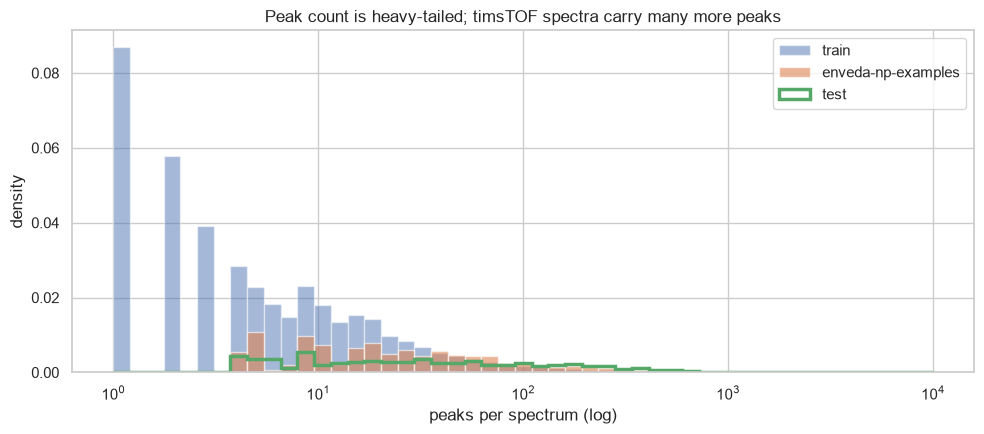

,train,np-examples,test
count,2539608.0,1184.0,1213.0
mean,158.0,257.0,330.0
std,517.0,320.0,349.0
min,1.0,4.0,4.0
25%,14.0,50.0,101.0
50%,42.0,142.0,230.0
75%,164.0,347.0,443.0
max,73318.0,3121.0,3259.0


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.logspace(0, 4, 50)
ax.hist(train.num_peaks.clip(1), bins=bins, density=True, alpha=.5, color=C_TRAIN, label="train")
ax.hist(np_ex.num_peaks.clip(1), bins=bins, density=True, alpha=.6, color=C_NP, label="enveda-np-examples")
ax.hist(test.num_peaks.clip(1), bins=bins, density=True, histtype="step", lw=2.5, color=C_TEST, label="test")
ax.set_xscale("log"); ax.set_xlabel("peaks per spectrum (log)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Peak count is heavy-tailed; timsTOF spectra carry many more peaks")
save(fig, "eda_06_num_peaks")
display(pd.DataFrame({"train": train.num_peaks.describe(), "np-examples": np_ex.num_peaks.describe(),
                      "test": test.num_peaks.describe()}).round(0))

test peaks: 400,707
  share of peaks below 0.1% of base peak: 76.5%
  share of peaks below 1.0% of base peak: 92.6%
  share of peaks below 2.0% of base peak: 94.8%


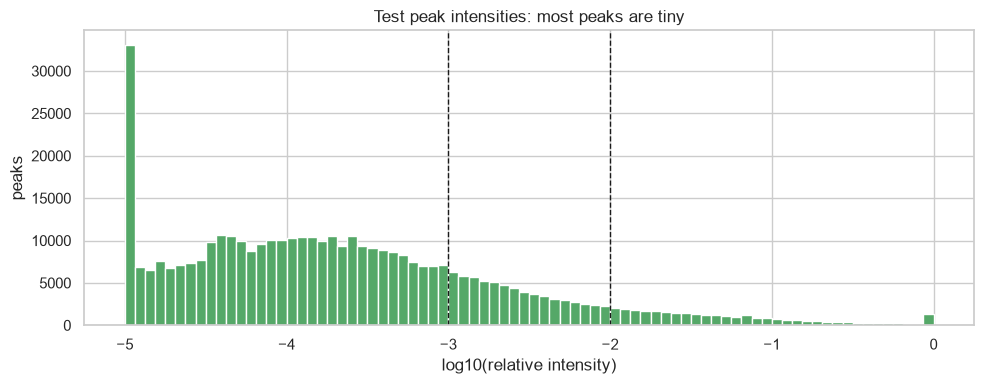

In [10]:
ints = np.concatenate(test.ms2_normalized_intensities.values)
print(f"test peaks: {ints.size:,}")
for thr in [0.001, 0.01, 0.02]:
    print(f"  share of peaks below {thr:.1%} of base peak: {(ints < thr).mean():.1%}")
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(np.log10(np.clip(ints, 1e-5, 1)), bins=80, color=C_TEST)
for thr in [0.001, 0.01]:
    ax.axvline(np.log10(thr), color="k", ls="--", lw=1)
ax.set_xlabel("log10(relative intensity)"); ax.set_ylabel("peaks"); ax.set_title("Test peak intensities: most peaks are tiny")
save(fig, "eda_07_intensity")

**Decision:** most test peaks sit below 1% of the base peak and are likely noise, and test spectra are much denser than the average library spectrum.
The baseline keeps peaks ≥ 1% of the base peak, at most the top 64, with sqrt-scaled intensities so a few large peaks don't dominate the cosine.

## 9. Collision energy

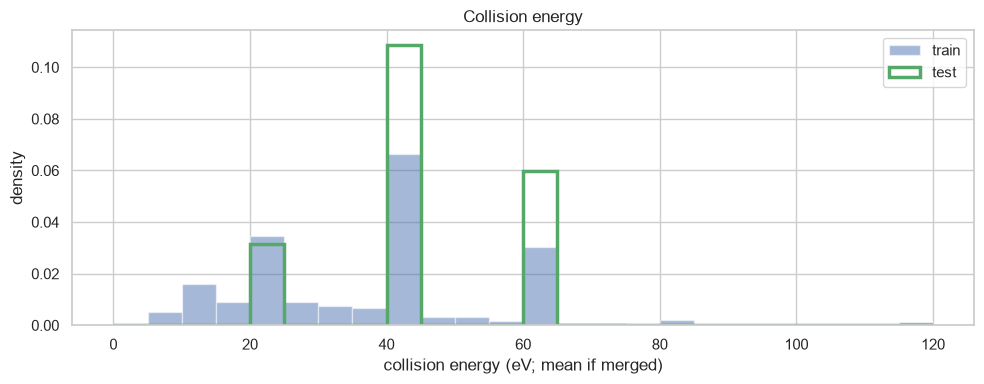

train spectra with no usable eV value: 13.3%
test spectra merged from several energies: 24.6%


In [11]:
def first_ce(x):
    try: return float(np.mean(x)) if x is not None and len(x) else np.nan
    except TypeError: return np.nan
ce_tr = train.collision_energy_ev.map(first_ce)
ce_te = test.collision_energy_ev.map(first_ce)
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 125, 5)
ax.hist(ce_tr.dropna().clip(upper=120), bins=bins, density=True, alpha=.5, color=C_TRAIN, label="train")
ax.hist(ce_te.dropna().clip(upper=120), bins=bins, density=True, histtype="step", lw=2.5, color=C_TEST, label="test")
ax.set_xlabel("collision energy (eV; mean if merged)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Collision energy")
save(fig, "eda_08_collision_energy")
print(f"train spectra with no usable eV value: {ce_tr.isna().mean():.1%}")
print(f"test spectra merged from several energies: {(test.collision_energy_ev.map(len) > 1).mean():.1%}")

## 10. Spectra per test molecule

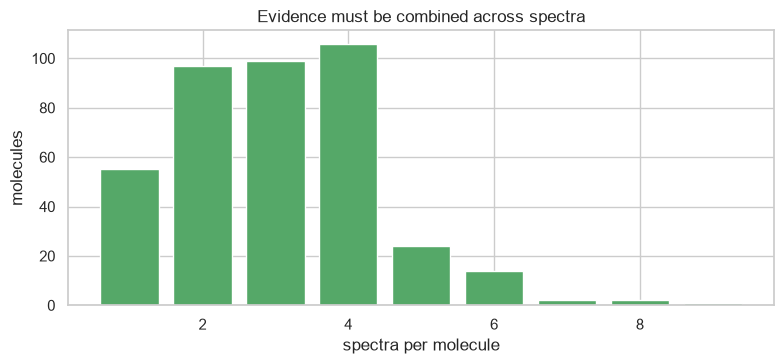

{'count': 400.0, 'mean': 3.0, 'std': 1.4, 'min': 1.0, '25%': 2.0, '50%': 3.0, '75%': 4.0, 'max': 9.0}
molecules with both ionisation modes: 0.242


In [12]:
per_mol = test.groupby("molecule_id").size()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(*np.unique(per_mol, return_counts=True), color=C_TEST)
ax.set_xlabel("spectra per molecule"); ax.set_ylabel("molecules"); ax.set_title("Evidence must be combined across spectra")
save(fig, "eda_09_spectra_per_molecule")
print(per_mol.describe().round(1).to_dict())
print("molecules with both ionisation modes:", (test.groupby('molecule_id').ionization_mode.nunique() > 1).mean().round(3))

**Decision:** most molecules have several spectra (median 3) and 24% have spectra in both ionisation modes, so the baseline averages, per candidate, the best cosine for each of the molecule's spectra.

## Summary of findings → design decisions

| # | Finding | Decision |
|---|---|---|
| 1 | 2.54M spectra / 275,810 structures from 11 libraries; enveda-180 is 45% of spectra but drug-like chemistry | Don't let enveda-180 dominate learned models; weight or subsample it |
| 2 | All 250 `enveda-np-examples` molecules (test instrument) also appear in another library | Use it as the validation set for library search; it only measures Class 1 molecules |
| 3 | Only 10% of structures appear in more than one library, yet those overlaps leak | Split learned-model validation **by `inchikey14`** |
| 4 | Test is 79% `[M+H]+`, 19% negative mode; 14% of train uses adducts never seen in test | Compare spectra within the same ionisation mode; drop non-test adducts for training |
| 5 | Median 15 candidate structures within 15 ppm; 38% of molecules have more than 25 | Mass alone can't rank isomers, so re-rank by spectral similarity |
| 6 | timsTOF precursor error is under 5 ppm; public libraries have a long tail of mislabelled spectra | 15 ppm window; filter |error| > 20 ppm when training |
| 7 | Test spectra have a median of 230 peaks; 93% of test peaks are below 1% of the base peak | Intensity floor 1%, top-64 peaks, sqrt scaling |
| 8 | 25% of test spectra merge several collision energies; 13% of train has no usable eV | Use `collision_energy_ev`; treat CE as optional input |
| 9 | Median 3 spectra per test molecule, up to 9 | Aggregate evidence per molecule, not per spectrum |